<a href="https://colab.research.google.com/github/pphantomfury/SemProject_MLEngine/blob/main/Synthetic_Donor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Downloading to /root/.cache/kagglehub/datasets/dbrown86/synthetic-donor-dataset-for-fundraising-analytics/4.archive... 100%|██████████| 155M/155M [00:00<00:00, 163MB/s]Extracting files... Path to dataset files: /root/.cache/kagglehub/datasets/dbrown86/synthetic-donor-dataset-for-fundraising-analytics/versions/4

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("dbrown86/synthetic-donor-dataset-for-fundraising-analytics")

print("Path to dataset files:", path)

100%|██████████| 155M/155M [00:00<00:00, 163MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/dbrown86/synthetic-donor-dataset-for-fundraising-analytics/versions/4


In [ ]:
import os

# List all files in the downloaded dataset directory
files = os.listdir(path)
print("Files in dataset directory:", files)

Files in dataset directory: ['dashboard_code_example.py', 'HOW_TO_USE_DASHBOARD_CODE.md', 'COLUMN_DESCRIPTIONS.md', 'dashboard_code_example.ipynb', 'kaggle_dataset', 'README.md']


In [ ]:
import os

# Explore the kaggle_dataset subfolder
subfolder_path = os.path.join(path, 'kaggle_dataset')
if os.path.exists(subfolder_path):
    print("Files in 'kaggle_dataset':", os.listdir(subfolder_path))
else:
    print("kaggle_dataset directory not found.")

# Read and display COLUMN_DESCRIPTIONS.md if it exists
col_desc_path = os.path.join(path, 'COLUMN_DESCRIPTIONS.md')
if os.path.exists(col_desc_path):
    with open(col_desc_path, 'r', encoding='utf-8') as f:
        print("\n--- COLUMN_DESCRIPTIONS.md Summary ---\n")
        print(f.read()[:1500]) # Print first 1500 characters to get an overview
else:
    print("COLUMN_DESCRIPTIONS.md not found.")

Files in 'kaggle_dataset': ['events.csv', 'donors.csv', 'family.csv', 'giving.csv', 'relationships.csv', 'README.md', 'contacts.csv']

--- COLUMN_DESCRIPTIONS.md Summary ---

# Kaggle Dataset Column Descriptions

This document provides detailed descriptions and data types for all columns in the synthetic donor dataset.

---

## 1. donors.csv (500,000 rows, 112 columns)

### Core Identifiers
| Column Name | Data Type | Null % | Description |
|------------|-----------|---------|-------------|
| `ID` | Integer | 0.0% | Unique donor identifier (primary key) |
| `First_Name` | String/Text | 0.0% | Donor first name |
| `Last_Name` | String/Text | 0.0% | Donor last name |
| `Full_Name` | String/Text | 0.0% | Donor full name (First + Last) |

### Demographics & Classification
| Column Name | Data Type | Null % | Description |
|------------|-----------|---------|-------------|
| `Gender` | String/Text | 0.0% | Donor gender (M/F/Other) |
| `donor_type` | String/Text | 0.0% | Primary constituent 

Load donors.csv into a pandas DataFrame and display the first 5 rows

In [ ]:
import pandas as pd
import os

# Construct path to donors.csv
donors_path = os.path.join(subfolder_path, 'donors.csv')

# Load the dataset into a pandas DataFrame
donors_df = pd.read_csv(donors_path)

# Display the first 5 rows
display(donors_df.head())

,ID,First_Name,Last_Name,Full_Name,Gender,donor_type,Constituent_Type_2,Class_Year,Parent_Year,Primary_Manager,...,Gave_Again_In_2024,Gave_Again_In_2025,high_rating,network_size,degree_centrality,influence_score,high_influence_role,clustering_coefficient,has_estate_capacity,Will_Give_Again_Probability
0,770487,Kelly,Rodriguez,Kelly Rodriguez,F,Alum,Alum,2016.0,NaN,NaN,...,1,1,-0.036162,0.0,0.0,0.0,0.0,0.0,0.0,0.616044
1,216739,Nancy,Taylor,Nancy Taylor,F,Alum,NaN,2005.0,NaN,NaN,...,0,0,-0.036162,0.0,0.0,0.0,0.0,0.0,0.0,0.000389
2,126225,Charles,Taylor,Charles Taylor,M,Alum,Alum,2015.0,NaN,NaN,...,0,0,-0.036162,0.0,0.0,0.0,0.0,0.0,0.0,0.000388
3,877572,William,Hernandez,William Hernandez,M,Parent,NaN,NaN,2015.0,NaN,...,0,0,-0.036162,0.0,0.0,0.0,0.0,0.0,0.0,0.000388
4,388389,Andrew,Jones,Andrew Jones,M,Alum,Alum,2021.0,NaN,NaN,...,0,0,-0.036162,0.0,0.0,0.0,0.0,0.0,0.0,0.000388


Check for missing values and summary statistics in donors_df

In [ ]:
# Calculate missing values count and percentage
missing_count = donors_df.isnull().sum()
missing_percent = (missing_count / len(donors_df)) * 100

# Combine into a DataFrame for easier reading
missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Percentage (%)': missing_percent
}).sort_values(by='Missing Count', ascending=False)

# Display the top 20 columns with the most missing values
print("Top 20 columns with the highest missing values:")
display(missing_df.head(20))

Top 20 columns with the highest missing values:


,Missing Count,Percentage (%)
Primary_Manager,497750,99.5500
Board_Affiliations,496826,99.3652
Family_ID,408408,81.6816
Relationship_Type,408408,81.6816
Constituent_Type_2,350139,70.0278
Parent_Year,314765,62.9530
index,277662,55.5324
Class_Year,214552,42.9104
Last_Gift_Date,199831,39.9662
Last_Gift_Designation,199831,39.9662


In [ ]:
# Summary statistics for numerical columns
print("Summary statistics for numerical columns:")
display(donors_df.describe())

# Summary statistics for categorical columns
print("\nSummary statistics for categorical columns:")
display(donors_df.describe(include=['object', 'category']))

Summary statistics for numerical columns:


,ID,Class_Year,Parent_Year,Lifetime_Giving,Last_Gift,Consecutive_Yr_Giving_Count,Total_Yr_Giving_Count,Family_ID,Engagement_Score,Legacy_Intent_Probability,...,Gave_Again_In_2024,Gave_Again_In_2025,high_rating,network_size,degree_centrality,influence_score,high_influence_role,clustering_coefficient,has_estate_capacity,Will_Give_Again_Probability
count,500000.000000,285448.000000,185235.000000,5.000000e+05,5.000000e+05,500000.000000,500000.000000,91592.000000,500000.000000,500000.000000,...,500000.000000,500000.000000,5.000000e+05,500000.0,500000.0,500000.0,500000.0,500000.0,500000.0,500000.000000
mean,549745.964042,2007.874044,2017.066845,6.219600e+04,1.698963e+04,3.421818,7.871896,26674.021618,32.813729,0.265957,...,0.292686,0.300780,1.389111e-17,0.0,0.0,0.0,0.0,0.0,0.0,0.361422
std,259865.130891,13.341187,7.086802,7.924662e+05,2.387233e+05,5.764444,11.523615,9618.336124,14.503560,0.160179,...,0.454996,0.458598,1.000001e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.386827
min,100000.000000,1950.000000,1990.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,10000.000000,10.000000,0.100000,...,0.000000,0.000000,-3.616224e-02,0.0,0.0,0.0,0.0,0.0,0.0,0.000384
25%,324384.750000,2000.000000,2013.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,18326.750000,22.000000,0.100000,...,0.000000,0.000000,-3.616224e-02,0.0,0.0,0.0,0.0,0.0,0.0,0.000388
50%,549873.500000,2010.000000,2019.000000,4.414700e+02,9.824000e+01,0.000000,1.000000,26689.500000,31.000000,0.300000,...,0.000000,0.000000,-3.616224e-02,0.0,0.0,0.0,0.0,0.0,0.0,0.000390
75%,774680.750000,2019.000000,2023.000000,8.319245e+03,2.010213e+03,5.000000,13.000000,35011.250000,41.100000,0.400000,...,1.000000,1.000000,-3.616224e-02,0.0,0.0,0.0,0.0,0.0,0.0,0.786741
max,999998.000000,2025.000000,2025.000000,1.000000e+08,4.131660e+07,25.000000,50.000000,43332.000000,100.000000,0.750000,...,1.000000,1.000000,2.765315e+01,0.0,0.0,0.0,0.0,0.0,0.0,0.939212



Summary statistics for categorical columns:


,First_Name,Last_Name,Full_Name,Gender,donor_type,Constituent_Type_2,Primary_Manager,Rating,Prospect_Stage,Last_Gift_Designation,Last_Gift_Date,Rating_Giving_Alignment,Relationship_Type,Family_Giving_Potential,region,Professional_Background,Interest_Keywords,Board_Affiliations
count,500000,500000,500000,500000,500000,149861,2250,500000,500000,300169,300169,500000,91592,500000,500000,500000,500000,3174
unique,98,52,5096,2,8,3,15,16,5,27,16449,3,4,4,7,14,1464,83
top,Janet,Smith,Sarah Smith,M,Alum,Parent,Kevin Wu,L,Identification,Annual Fund,2025-04-13,Aligned,Head,Individual,Northeast,Government,Environment,Corporate Board
freq,10011,36605,749,250356,275563,50103,150,75165,225087,11308,116,495023,33333,408408,71966,36073,21050,416



Create a histogram for the 'Estimated_Age' column

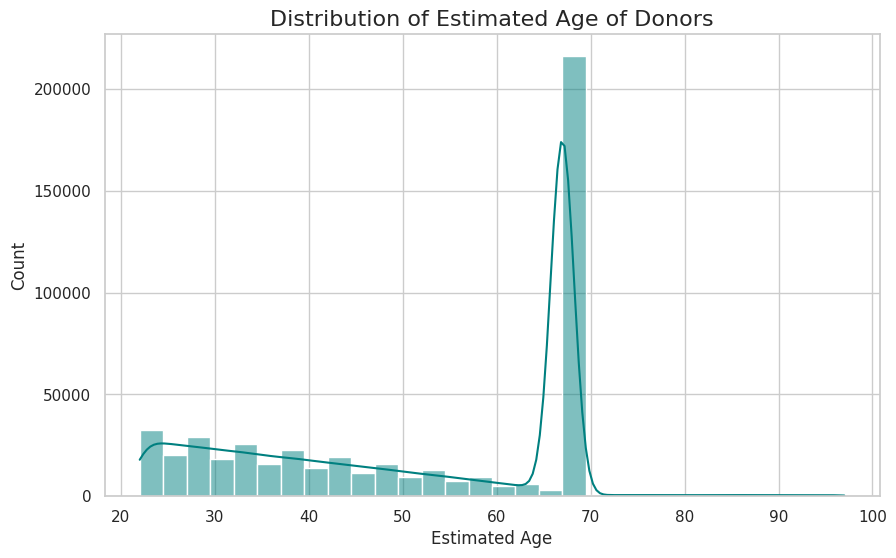

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style and figure size
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Create the histogram with a kernel density estimate (KDE)
sns.histplot(data=donors_df, x='Estimated_Age', bins=30, kde=True, color='teal')

# Add labels and title
plt.title('Distribution of Estimated Age of Donors', fontsize=16)
plt.xlabel('Estimated Age', fontsize=12)
plt.ylabel('Count', fontsize=12)

# Display the plot
plt.show()

### 1. Machine Learning Approach & Algorithm Identification
Based on the variables inside `donors.csv` and the supporting fundraising files, the primary objective is to optimize fundraising efforts, predict donor retention, and target major donors. Two main ML approaches are highly relevant:

* **Supervised Learning (Classification):**
  * **Target Variable:** `Gave_Again_In_2025` or predicting high probability thresholds in `Will_Give_Again_Probability`.
  * **Algorithms:** XGBoost, LightGBM, or Random Forest. These ensemble tree models are ideal because they handle mixed data types (categorical professional backgrounds, continuous age, and numeric giving metrics) and handle missing data exceptionally well.
* **Unsupervised Learning (Clustering):**
  * **Target Objective:** Donor segmentation to group donors based on affinity and wealth capacity.
  * **Algorithms:** K-Means Clustering or Hierarchical Clustering (using key features like `Lifetime_Giving`, `Engagement_Score`, and `Estimated_Age`).

---

### 2. Data Cleaning Process & Roadmap
To transform the raw exploration dataset into a model-ready final state, the following critical data-cleaning steps must be taken:
1. **Feature Dropping:** Drop high-cardinality metadata columns that lack predictive value (such as `ID`, `First_Name`, `Last_Name`, `Full_Name`, and `index`).
2. **Handling Highly Sparse Features:** Remove columns with extreme missingness, such as `Primary_Manager` (99.55% missing) and `Board_Affiliations` (99.36% missing), as they introduce noise rather than signal.
3. **Addressing Structural Missingness:** Columns like `Class_Year` and `Parent_Year` are null for non-alumni/non-parents. We should create binary indicator flags (e.g., `is_alum`, `is_parent`) and impute missing years with a sentinel value (e.g., `-1` or `0`).
4. **Imputation of Numerical Artifacts:** Address the age anomalies (the major spike at ~68 years) by either treating it as an input category or using robust median/mean imputation within specific `donor_type` sub-segments.
5. **Encoding Categorical Variables:** Convert high-impact categorical features (like `region`, `Professional_Background`, and `donor_type`) into numeric representations using One-Hot Encoding or Target Encoding.

---

### 3. Four Key Observations Derived from Exploratory Data Analysis (EDA)
From our initial exploration and profiling, we have uncovered the following distinct observations:

1. **Severe Giving Distribution Skewness:** The `Lifetime_Giving` attribute has a median of only `$441.47`, whereas the maximum is `$100,000,000`. This confirms a highly skewed Pareto distribution (power-law distribution), showing that a tiny minority of major donors provide the vast majority of financial support.
2. **The Synthetic Age 'Sentinel' Spike:** The histogram of `Estimated_Age` reveals a steady downward trend from age 22 to 65, which is suddenly interrupted by an extremely high artificial peak around age 68. This is a critical artifact of the synthetic generation, indicating a default fallback or imputation bias in the source generator.
3. **Alumni Dominance in Constituent Mix:** In the categorical analysis, `donor_type` reveals that **Alumni** (Alum) represent over 55% of the total dataset (`275,563` out of 500,000), showing that the fundraising ecosystem is heavily dependent on academic graduates.
4. **Relational Data Sparsity:** Only ~18.3% of records have an associated `Family_ID` and `Relationship_Type`. This indicates that network-level relationships and family-based tracking are highly sparse, meaning models relying on household parameters must handle missing relationship structures effectively.